# Bolt Send × eWAKA: predicting courier performance
**Team:** Sinhye Kim, Yan Wu, Wei-Chia Lin, Ethan Casey

This notebook answers challenge **Q3 (prediction objective)** with two models that eWAKA's operations team can use:

| Model | Question | Unit | eWAKA use |
|---|---|---|---|
| **A. No-response risk** | Will this courier fail to respond to this offer? | one order offer | real-time nudges; evidence for Bolt to space out offers |
| **B. Next-week low performer** | Will this courier's finish rate fall below 50% next week? | courier-week | weekly coaching list |

Both models use only information available **before** the moment of prediction, and both are tested on a **later time period** than they were trained on.

**Data:** `boltsend_rider_history.xlsx` (110,578 order events) and `boltsend_rider_perfomance.xlsx` (15,351 courier-days), Jan 2025 – Aug 2026. Optional rides are excluded throughout. Place both files next to this notebook to re-run it.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_score, recall_score
from sklearn.inspection import permutation_importance

GREEN, ORANGE, TEAL, RED, GRAY = '#1F7A4D', '#D4690F', '#1B7A83', '#B5392F', '#6B7B74'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

hist = pd.read_excel('boltsend_rider_history.xlsx')
perf = pd.read_excel('boltsend_rider_perfomance.xlsx')
print(hist.shape, perf.shape)

(110578, 21) (15351, 16)


In [2]:
hist['dt'] = pd.to_datetime(hist['date'].str[:19])          # local Nairobi time
hist['moto'] = hist['vehicle_model'].isin(['eWAKA Jasiri', 'RhingGo M300']).astype(int)
o = hist[hist['optional_ride'].isna()].sort_values(['individual_identifier', 'dt']).reset_index(drop=True)
o['nr'] = (o['status'] == 'Driver did not respond').astype(int)
print(f"{len(o):,} non-optional offers | no-response rate {o['nr'].mean():.1%}")
print(o.groupby('moto')['nr'].mean().rename({0: 'bicycle', 1: 'motorbike'}).round(3))

104,396 non-optional offers | no-response rate 9.9%
moto
bicycle      0.095
motorbike    0.140
Name: nr, dtype: float64


## A. No-response risk for each offer

**Target:** the offer ends as *Driver did not respond*.

**Features** (all known when the offer is sent):
- `gap_min` minutes since the courier's previous offer; `burst` = previous offer under 10 minutes ago
- `offers_last60` offers the courier received in the previous 60 minutes
- `intrip` courier is still on an earlier trip (previous trip's fare not yet finalised)
- `hour`, `dow`; `offers_today`, `hrs_since_first_today`
- `prev_nr` previous offer was missed; `nr_rate_prev50` courier's no-response rate over their previous 50 offers; `hist_n` offers handled so far
- `moto` motorbike

In [3]:
g = o.groupby('individual_identifier')
o['gap_min'] = ((o['dt'] - g['dt'].shift()).dt.total_seconds() / 60).fillna(24 * 60).clip(upper=24 * 60)
o['burst'] = (o['gap_min'] < 10).astype(int)

def offers_last60(df):
    t = df['dt'].values.astype('datetime64[s]').astype(np.int64)
    return pd.Series(np.arange(len(t)) - np.searchsorted(t, t - 3600, side='left'), index=df.index)
o['offers_last60'] = g.apply(offers_last60).reset_index(level=0, drop=True)

o['fin_end'] = pd.to_datetime(o['fare_finalised'].str[:19], errors='coerce')
o['busy_until'] = g['fin_end'].transform(lambda s: s.shift(1).cummax())
o['intrip'] = (o['busy_until'] > o['dt']).astype(int)

o['hour'], o['dow'], o['day'] = o['dt'].dt.hour, o['dt'].dt.dayofweek, o['dt'].dt.normalize()
o['offers_today'] = o.groupby(['individual_identifier', 'day']).cumcount()
o['hrs_since_first_today'] = (o['dt'] - o.groupby(['individual_identifier', 'day'])['dt'].transform('min')).dt.total_seconds() / 3600
o['prev_nr'] = g['nr'].shift().fillna(0)
o['nr_rate_prev50'] = g['nr'].transform(lambda s: s.shift().rolling(50, min_periods=5).mean())
o['hist_n'] = g.cumcount()

FEATS_A = ['gap_min', 'burst', 'offers_last60', 'intrip', 'hour', 'dow', 'offers_today',
           'hrs_since_first_today', 'prev_nr', 'nr_rate_prev50', 'hist_n', 'moto']

CUT_A = pd.Timestamp('2026-03-01')
train, test = o[o['dt'] < CUT_A].copy(), o[o['dt'] >= CUT_A].copy()
fill = train['nr'].mean()
for d in (train, test):
    d['nr_rate_prev50'] = d['nr_rate_prev50'].fillna(fill)
print(f"train {len(train):,} offers (Jan 2025 - Feb 2026), NR {train['nr'].mean():.1%}")
print(f"test  {len(test):,} offers (Mar - Aug 2026),   NR {test['nr'].mean():.1%}")

train 93,630 offers (Jan 2025 - Feb 2026), NR 9.2%
test  10,766 offers (Mar - Aug 2026),   NR 15.7%


In [4]:
logit_A = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(train[FEATS_A], train['nr'])
gb_A = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, random_state=0).fit(train[FEATS_A], train['nr'])

test['p_logit'] = logit_A.predict_proba(test[FEATS_A])[:, 1]
test['p_gb'] = gb_A.predict_proba(test[FEATS_A])[:, 1]

def top_decile(y, p):
    q = pd.qcut(p, 10, labels=False, duplicates='drop')
    top = q == q.max()
    return y[top].mean(), y[top].sum() / y.sum()

rows = []
for name, p in [('Baseline: courier history only', test['nr_rate_prev50']),
                ('Logistic regression', test['p_logit']),
                ('Gradient boosting', test['p_gb'])]:
    td_rate, td_capture = top_decile(test['nr'].values, np.asarray(p))
    mt = test['moto'] == 1
    rows.append({'model': name, 'AUC': roc_auc_score(test['nr'], p), 'AUC motorbike': roc_auc_score(test['nr'][mt], np.asarray(p)[mt.values]),
                 'avg precision': average_precision_score(test['nr'], p),
                 'NR rate in top 10% risk': td_rate, 'share of all NR caught in top 10%': td_capture})
res_A = pd.DataFrame(rows).set_index('model')
res_A.style.format('{:.3f}') if False else res_A.round(3)

,AUC,AUC motorbike,avg precision,NR rate in top 10% risk,share of all NR caught in top 10%
model,,,,,
Baseline: courier history only,0.713,0.703,0.324,0.393,0.227
Logistic regression,0.734,0.729,0.364,0.436,0.278
Gradient boosting,0.748,0.744,0.379,0.457,0.291


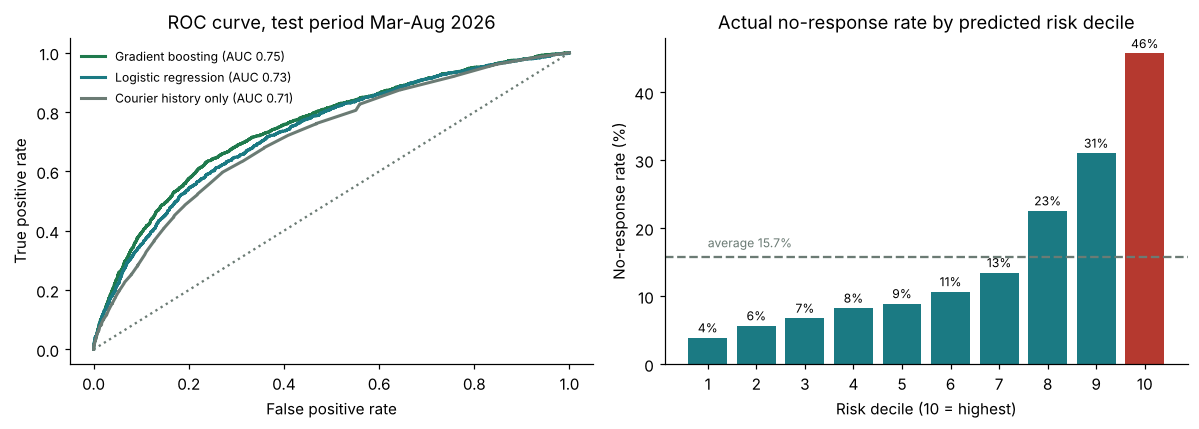

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, col, c in [('Gradient boosting', 'p_gb', GREEN), ('Logistic regression', 'p_logit', TEAL), ('Courier history only', 'nr_rate_prev50', GRAY)]:
    fpr, tpr, _ = roc_curve(test['nr'], test[col])
    axes[0].plot(fpr, tpr, color=c, lw=2, label=f"{name} (AUC {roc_auc_score(test['nr'], test[col]):.2f})")
axes[0].plot([0, 1], [0, 1], ls=':', color=GRAY)
axes[0].set(title='ROC curve, test period Mar-Aug 2026', xlabel='False positive rate', ylabel='True positive rate')
axes[0].legend(frameon=False, fontsize=8)

test['decile'] = pd.qcut(test['p_gb'], 10, labels=False, duplicates='drop') + 1
dec = test.groupby('decile')['nr'].mean() * 100
axes[1].bar(dec.index, dec.values, color=[RED if i == dec.index.max() else TEAL for i in dec.index])
axes[1].axhline(test['nr'].mean() * 100, ls='--', color=GRAY)
axes[1].text(1, test['nr'].mean() * 100 + 1.5, f"average {test['nr'].mean():.1%}", color=GRAY, fontsize=8)
for x, v in zip(dec.index, dec.values):
    axes[1].text(x, v + 0.8, f"{v:.0f}%", ha='center', fontsize=8)
axes[1].set(title='Actual no-response rate by predicted risk decile', xlabel='Risk decile (10 = highest)', ylabel='No-response rate (%)', xticks=range(1, 11))
plt.tight_layout(); plt.show()

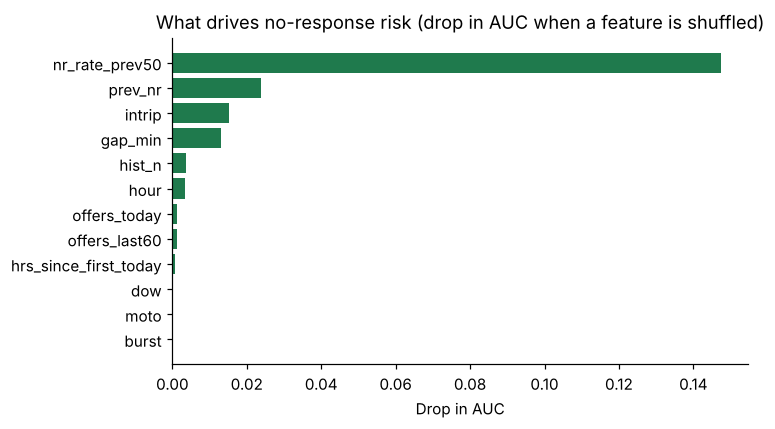

In [6]:
imp = permutation_importance(gb_A, test[FEATS_A], test['nr'], scoring='roc_auc', n_repeats=5, random_state=0)
imp_A = pd.Series(imp.importances_mean, index=FEATS_A).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp_A.index, imp_A.values, color=GREEN)
ax.set(title='What drives no-response risk (drop in AUC when a feature is shuffled)', xlabel='Drop in AUC')
plt.tight_layout(); plt.show()

In [7]:
# Situations the model flags, in plain terms (motorbike offers, test period)
mt = test[test['moto'] == 1]
sit = pd.DataFrame({
    'offers': [len(mt), mt['burst'].sum(), mt['intrip'].sum(), (mt['prev_nr'] == 1).sum()],
    'actual NR rate': [mt['nr'].mean(), mt.loc[mt['burst'] == 1, 'nr'].mean(), mt.loc[mt['intrip'] == 1, 'nr'].mean(), mt.loc[mt['prev_nr'] == 1, 'nr'].mean()],
    'mean predicted risk': [mt['p_gb'].mean(), mt.loc[mt['burst'] == 1, 'p_gb'].mean(), mt.loc[mt['intrip'] == 1, 'p_gb'].mean(), mt.loc[mt['prev_nr'] == 1, 'p_gb'].mean()],
}, index=['all motorbike offers', 'previous offer < 10 min ago', 'courier still on a trip', 'previous offer missed'])
sit.round(3)

,offers,actual NR rate,mean predicted risk
all motorbike offers,9537,0.141,0.164
previous offer < 10 min ago,2893,0.231,0.237
courier still on a trip,794,0.239,0.251
previous offer missed,1336,0.349,0.351


### What model A means for operations
- Courier history alone already ranks risk reasonably (AUC ≈ 0.71). Adding **the situation of the offer** (bursts, mid-trip, a just-missed offer, time of day) lifts AUC to about **0.75**.
- The **top 10% riskiest offers** miss about **46%** of the time, roughly **3×** the average, and contain about **29%** of all missed offers.
- **eWAKA:** when a courier's live risk is high (e.g. just missed an offer and another arrives within minutes), send a nudge or suggest going offline.
- **Bolt:** skip or delay offers to couriers in a high-risk state and send them to the next courier, cutting reassignment delay.
- AUC 0.75 is useful for ranking, not for certainty. Reasons for missing (phone out of reach, riding, on a break) are not in the data.

## B. Next-week low performer

**Target:** next week's finish rate (finished ÷ non-optional offers) is **below 50%**.
**Sample:** courier-weeks with at least 10 offers in the week and in the following week.
**Features (this week):** offers, outcome mix (no-response, rejected, customer cancelled, courier cancelled, finished), mid-trip and burst shares, active days, median pickup / ride time and distance, online hours, utilisation, acceptance rate, rating, driver score, any non-active status, tenure in weeks, motorbike, fare per online hour.
**Baseline:** "next week looks like this week" (1 − this week's finish rate).

In [8]:
o['wk'] = o['dt'].dt.to_period('W-SUN').dt.start_time
o['fin'] = (o['status'] == 'Finished').astype(int)
o['rej'] = (o['status'] == 'Driver rejected').astype(int)
o['cust'] = o['status'].isin(['Rider cancelled', 'Rider did not show']).astype(int)
o['dcx'] = (o['status'] == 'Driver cancelled').astype(int)

w = o.groupby(['individual_identifier', 'wk']).agg(
    offers=('nr', 'size'), nr=('nr', 'mean'), rej=('rej', 'mean'), fin=('fin', 'mean'), cust=('cust', 'mean'), dcx=('dcx', 'mean'),
    intrip=('intrip', 'mean'), burst=('burst', 'mean'), active_days=('day', 'nunique'), moto=('moto', 'max'))
fo = o[o['status'] == 'Finished']
w = w.join(fo.groupby(['individual_identifier', 'wk']).agg(
    pickup=('pickup_duration_min', 'median'), ride=('ride_duration_min', 'median'), dist=('distancekm', 'median'), fare=('trip_priceksh', 'sum')))

perf['wk'] = pd.to_datetime(perf['report_date']).dt.to_period('W-SUN').dt.start_time
w = w.join(perf.groupby(['individual_identifier', 'wk']).agg(
    online_h=('online_time_min', lambda s: s.sum() / 60), util=('utilisation', 'mean'), acc=('total_acceptance_rate', 'mean'),
    rating=('average_driver_rating', lambda s: s[s > 0].mean()), score=('driver_score', 'mean'), susp=('status', lambda s: (s != 'Active').any())), how='left')
w = w.reset_index().sort_values(['individual_identifier', 'wk'])
w['tenure_wk'] = (w['wk'] - w.groupby('individual_identifier')['wk'].transform('min')).dt.days // 7
w['fare_per_h'] = w['fare'] / w['online_h'].replace(0, np.nan)
gw = w.groupby('individual_identifier')
for c in ['wk', 'fin', 'offers']:
    w['next_' + c] = gw[c].shift(-1)
w = w[((w['next_wk'] - w['wk']).dt.days == 7) & (w['offers'] >= 10) & (w['next_offers'] >= 10)].copy()
w['y'] = (w['next_fin'] < 0.5).astype(int)

FEATS_B = ['offers', 'nr', 'rej', 'fin', 'cust', 'dcx', 'intrip', 'burst', 'active_days', 'pickup', 'ride', 'dist',
           'online_h', 'util', 'acc', 'rating', 'score', 'susp', 'tenure_wk', 'moto', 'fare_per_h']
CUT_B = pd.Timestamp('2026-01-01')
trB, teB = w[w['wk'] < CUT_B], w[w['wk'] >= CUT_B]
med = trB[FEATS_B].astype(float).median()
XtrB, XteB = trB[FEATS_B].astype(float).fillna(med), teB[FEATS_B].astype(float).fillna(med)
print(f"{len(w):,} courier-weeks | train {len(trB):,} (2025) low-performer share {trB['y'].mean():.0%}"
      f" | test {len(teB):,} (Jan-Aug 2026) share {teB['y'].mean():.0%}, of which motorbike {teB['moto'].sum()}")

2,088 courier-weeks | train 1,894 (2025) low-performer share 24% | test 194 (Jan-Aug 2026) share 40%, of which motorbike 95


In [9]:
logit_B = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5)).fit(XtrB, trB['y'])
gb_B = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=3, random_state=0).fit(XtrB, trB['y'])
preds_B = {'Baseline: this week repeats': 1 - teB['fin'],
           'Logistic regression': logit_B.predict_proba(XteB)[:, 1],
           'Gradient boosting': gb_B.predict_proba(XteB)[:, 1]}
rows = []
for name, p in preds_B.items():
    p = np.asarray(p); y = teB['y'].values; mt = teB['moto'].values == 1
    rows.append({'model': name, 'AUC': roc_auc_score(y, p), 'AUC motorbike': roc_auc_score(y[mt], p[mt]),
                 'avg precision': average_precision_score(y, p),
                 'recall @0.5': recall_score(y, p >= 0.5), 'precision @0.5': precision_score(y, p >= 0.5, zero_division=0)})
res_B = pd.DataFrame(rows).set_index('model')
res_B.round(3)

,AUC,AUC motorbike,avg precision,recall @0.5,precision @0.5
model,,,,,
Baseline: this week repeats,0.902,0.918,0.855,0.808,0.788
Logistic regression,0.927,0.926,0.914,0.718,0.862
Gradient boosting,0.887,0.888,0.838,0.744,0.784


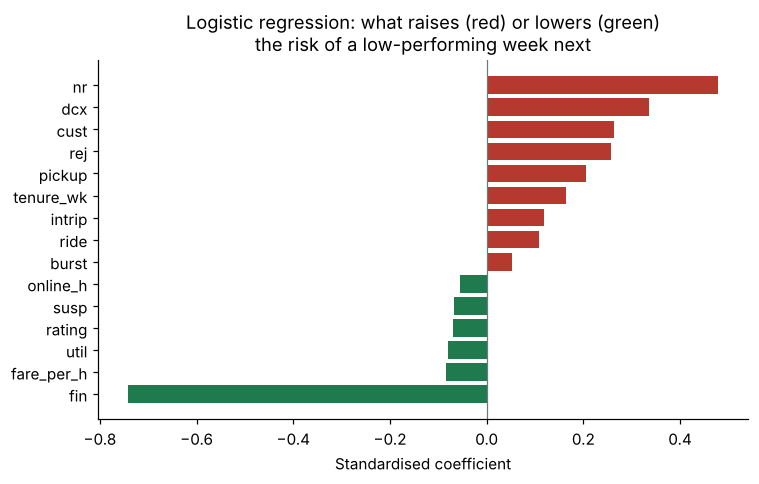

In [10]:
coef_B = pd.Series(logit_B[-1].coef_[0], index=FEATS_B).sort_values()
coef_B = coef_B[coef_B.abs() >= 0.05]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(coef_B.index, coef_B.values, color=[RED if v > 0 else GREEN for v in coef_B.values])
ax.axvline(0, color=GRAY, lw=0.8)
ax.set(title='Logistic regression: what raises (red) or lowers (green)\nthe risk of a low-performing week next', xlabel='Standardised coefficient')
plt.tight_layout(); plt.show()

In [11]:
# Example output for eWAKA: coaching list for one test week
latest = teB.groupby('wk').size().idxmax()   # busiest week in the test period
cur = teB[teB['wk'] == latest].copy()
cur['risk'] = logit_B.predict_proba(XteB.loc[cur.index])[:, 1]
def reason(r):
    out = []
    if r['nr'] >= 0.20: out.append(f"no-response {r['nr']:.0%}")
    if r['cust'] >= 0.35: out.append(f"customer cancellations {r['cust']:.0%}")
    if r['dcx'] >= 0.05: out.append(f"courier cancellations {r['dcx']:.0%}")
    if r['tenure_wk'] <= 2: out.append('new courier')
    if r['fin'] < 0.5: out.append(f"finish rate {r['fin']:.0%}")
    return ', '.join(out) or '-'
cur['flag'] = cur.apply(reason, axis=1)
cur['courier'] = cur['individual_identifier'].str[:8]
print('Coaching list, week of', latest.date(), '| couriers:', len(cur))
cur.sort_values('risk', ascending=False)[['courier', 'offers', 'fin', 'nr', 'risk', 'flag']].head(8).round(2)

Coaching list, week of 2026-02-09 | couriers: 15


,courier,offers,fin,nr,risk,flag
1627,Courier 01,52,0.23,0.46,0.94,"no-response 46%, courier cancellations 17%, finish rate 23%"
1550,Courier 02,105,0.28,0.44,0.92,"no-response 44%, finish rate 28%"
1938,Courier 03,16,0.25,0.56,0.86,"no-response 56%, courier cancellations 12%, finish rate 25%"
483,Courier 04,80,0.35,0.20,0.82,"no-response 20%, finish rate 35%"
1184,Courier 05,50,0.36,0.46,0.80,"no-response 46%, finish rate 36%"
443,Courier 06,30,0.43,0.43,0.75,"no-response 43%, finish rate 43%"
318,Courier 07,25,0.44,0.40,0.71,"no-response 40%, finish rate 44%"
136,Courier 08,41,0.49,0.32,0.62,"no-response 32%, courier cancellations 7%, finish rate 49%"


### What model B means for operations
- This week's finish rate alone already predicts next week well (AUC ≈ 0.90): performance is persistent.
- The logistic model adds a little (AUC ≈ 0.93 in the test period). Beyond the finish rate, **a high no-response share** is the strongest warning sign, followed by courier cancellations, customer cancellations and rejections; more online hours and a higher rating lower the risk.
- **eWAKA use:** each week, rank active couriers by risk and attach the reason (e.g. "no-response 31%"), feeding the scorecard and the first-two-week programme.
- Treat this as a **triage tool**: the gain over the simple baseline is modest, and the test period has only 194 courier-weeks (95 motorbike).

## Limitations
- Few motorbike couriers (about 20 active), so both models are trained mostly on bicycle history; motorbike AUCs are reported separately.
- No location, customer ID or exit reasons in the data.
- `intrip` is inferred from fare-finalised times; offers sent while a courier is between pickup and drop-off of a cancelled trip are not captured.
- Exit / churn prediction is left as a descriptive analysis: only 23 new motorbike couriers.